# Sprint 11 · Reto de visión artificial con un dataset real de Kaggle

**Proyecto:** Clasificación de fotografías de estancias de viviendas  
**Dataset:** [House Rooms – Kaggle](https://www.kaggle.com/datasets/annielu21/house-rooms)  
**Clases utilizadas:** baño, dormitorio, cocina, salón y jardín/exterior.

> Este cuaderno conserva el recorrido del reto S11_04: preparar los datos, entrenar, comparar modelos, evaluar, analizar errores, elegir un umbral de confianza y crear un demostrador. La diferencia es que ahora se trabaja con fotografías reales descargadas de Kaggle, no con dibujos sintéticos.

**Importante:** las cinco clases elegidas son una selección del dataset. No representan tipos de alojamiento (hotel, camping, etc.), sino tipos de estancias/espacios. Si el contenido descargado no incluye alguna de estas carpetas, el cuaderno se detendrá y mostrará las clases encontradas para que se pueda adaptar la selección.

## 0. Preparación del entorno

Ejecuta esta celda primero. En Colab se instalará `kagglehub`, que permite descargar datasets públicos de Kaggle. Si Kaggle solicita autenticación, sigue las instrucciones de la sección 1.

In [ ]:
!pip -q install kagglehub

import os, re, shutil, random, pathlib, json, math, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    f1_score, precision_recall_fscore_support
)
from PIL import Image
from collections import Counter

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU disponible: False


## 1. Descargar el dataset de Kaggle

Usaremos el dataset público **House Rooms** de Kaggle. El cuaderno intenta descargarlo con `kagglehub`.

Si la descarga solicita credenciales:
1. En Kaggle, entra en *Settings → API → Create New Token*.
2. Se descargará `kaggle.json`.
3. En Colab, abre el panel de archivos (icono de carpeta), súbelo a `/root/.kaggle/`.
4. Ejecuta de nuevo la celda de descarga.

No compartas ni subas `kaggle.json` a GitHub: contiene credenciales privadas.

In [ ]:
import kagglehub

DATASET_KAGGLE = "annielu21/house-rooms"

try:
    RUTA_DESCARGA = kagglehub.dataset_download(DATASET_KAGGLE)
    print("Dataset descargado en:", RUTA_DESCARGA)
except Exception as e:
    print("No se pudo descargar automáticamente.")
    print("Comprueba el acceso a Kaggle y, si lo solicita, configura kaggle.json.")
    raise e

Using Colab cache for faster access to the 'house-rooms' dataset.
Dataset descargado en: /kaggle/input/house-rooms


### 1.1 Localizar las carpetas de imágenes y seleccionar las clases

El dataset House Rooms contiene imágenes organizadas por tipos de estancia. Para mantener un ejercicio manejable seleccionamos cinco clases comunes. El código busca las carpetas aunque estén dentro de una carpeta contenedora.

In [ ]:
# Nombre estándar de clase: posibles nombres de carpeta presentes en distintas versiones del dataset
ALIAS_CLASES = {
    "bathroom": ["bathroom", "bath", "baño"],
    "bedroom": ["bedroom", "bed", "dormitorio"],
    "kitchen": ["kitchen", "cocina"],
    "living": ["living", "livingroom", "living_room", "salon", "lounge"],
    "yard": ["yard", "garden", "outdoor", "outdoors", "patio", "jardín"]
}
EXTENSIONES = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def normalizar(nombre):
    nombre = nombre.lower().strip().replace(" ", "").replace("-", "").replace("_", "")
    return nombre

encontradas = {}
for raiz, dirs, archivos in os.walk(RUTA_DESCARGA):
    nombre = normalizar(os.path.basename(raiz))
    imagenes = [f for f in archivos if f.lower().endswith(EXTENSIONES)]
    if not imagenes:
        continue
    for clase, alias in ALIAS_CLASES.items():
        if nombre in [normalizar(a) for a in alias] and clase not in encontradas:
            encontradas[clase] = raiz

print("Carpetas reconocidas:")
for clase, carpeta in encontradas.items():
    print(f"  {clase}: {carpeta}")

CLASES = list(ALIAS_CLASES.keys())
faltan = [c for c in CLASES if c not in encontradas]
if faltan:
    print("\nNo se han localizado estas clases:", faltan)
    print("Carpetas de imágenes encontradas en el dataset:")
    for raiz, dirs, archivos in os.walk(RUTA_DESCARGA):
        if any(f.lower().endswith(EXTENSIONES) for f in archivos):
            print(" -", os.path.basename(raiz), "(", raiz, ")")
    raise ValueError("Adapta ALIAS_CLASES a los nombres de carpeta que aparecen arriba y vuelve a ejecutar esta celda.")

Carpetas reconocidas:
  bathroom: /kaggle/input/house-rooms/room-dataset/bathroom
  bedroom: /kaggle/input/house-rooms/room-dataset/bedroom
  kitchen: /kaggle/input/house-rooms/room-dataset/kitchen
  yard: /kaggle/input/house-rooms/room-dataset/yard
  living: /kaggle/input/house-rooms/room-dataset/living


### 1.2 Crear una carpeta limpia y contar imágenes por clase

Copiamos las imágenes a una estructura sencilla, una carpeta por etiqueta. También ignoramos archivos que no sean imágenes.

In [ ]:
RUTA_DATOS = "/content/datos_kaggle"
if os.path.isdir(RUTA_DATOS):
    shutil.rmtree(RUTA_DATOS)
os.makedirs(RUTA_DATOS, exist_ok=True)

for clase in CLASES:
    destino = os.path.join(RUTA_DATOS, clase)
    os.makedirs(destino, exist_ok=True)
    origen = encontradas[clase]
    archivos = sorted(f for f in os.listdir(origen) if f.lower().endswith(EXTENSIONES))
    for j, archivo in enumerate(archivos):
        ext = os.path.splitext(archivo)[1].lower()
        shutil.copy2(os.path.join(origen, archivo), os.path.join(destino, f"{clase}_{j:05d}{ext}"))

def contar_por_clase(ruta):
    conteo = {}
    for clase in sorted(os.listdir(ruta)):
        carpeta = os.path.join(ruta, clase)
        if os.path.isdir(carpeta):
            conteo[clase] = sum(f.lower().endswith(EXTENSIONES) for f in os.listdir(carpeta))
    return conteo

conteo = contar_por_clase(RUTA_DATOS)
display(pd.DataFrame({"clase": list(conteo.keys()), "imagenes": list(conteo.values())}))
assert len(conteo) == 5 and all(v > 0 for v in conteo.values())

,clase,imagenes
0,bathroom,740
1,bedroom,1083
2,kitchen,1207
3,living,1164
4,yard,1397


### 1.3 Inspección visual de las fotografías

Antes de entrenar, observa ejemplos. Comprueba que las imágenes corresponden a la carpeta y anota etiquetas dudosas o fotografías que no aporten información útil.

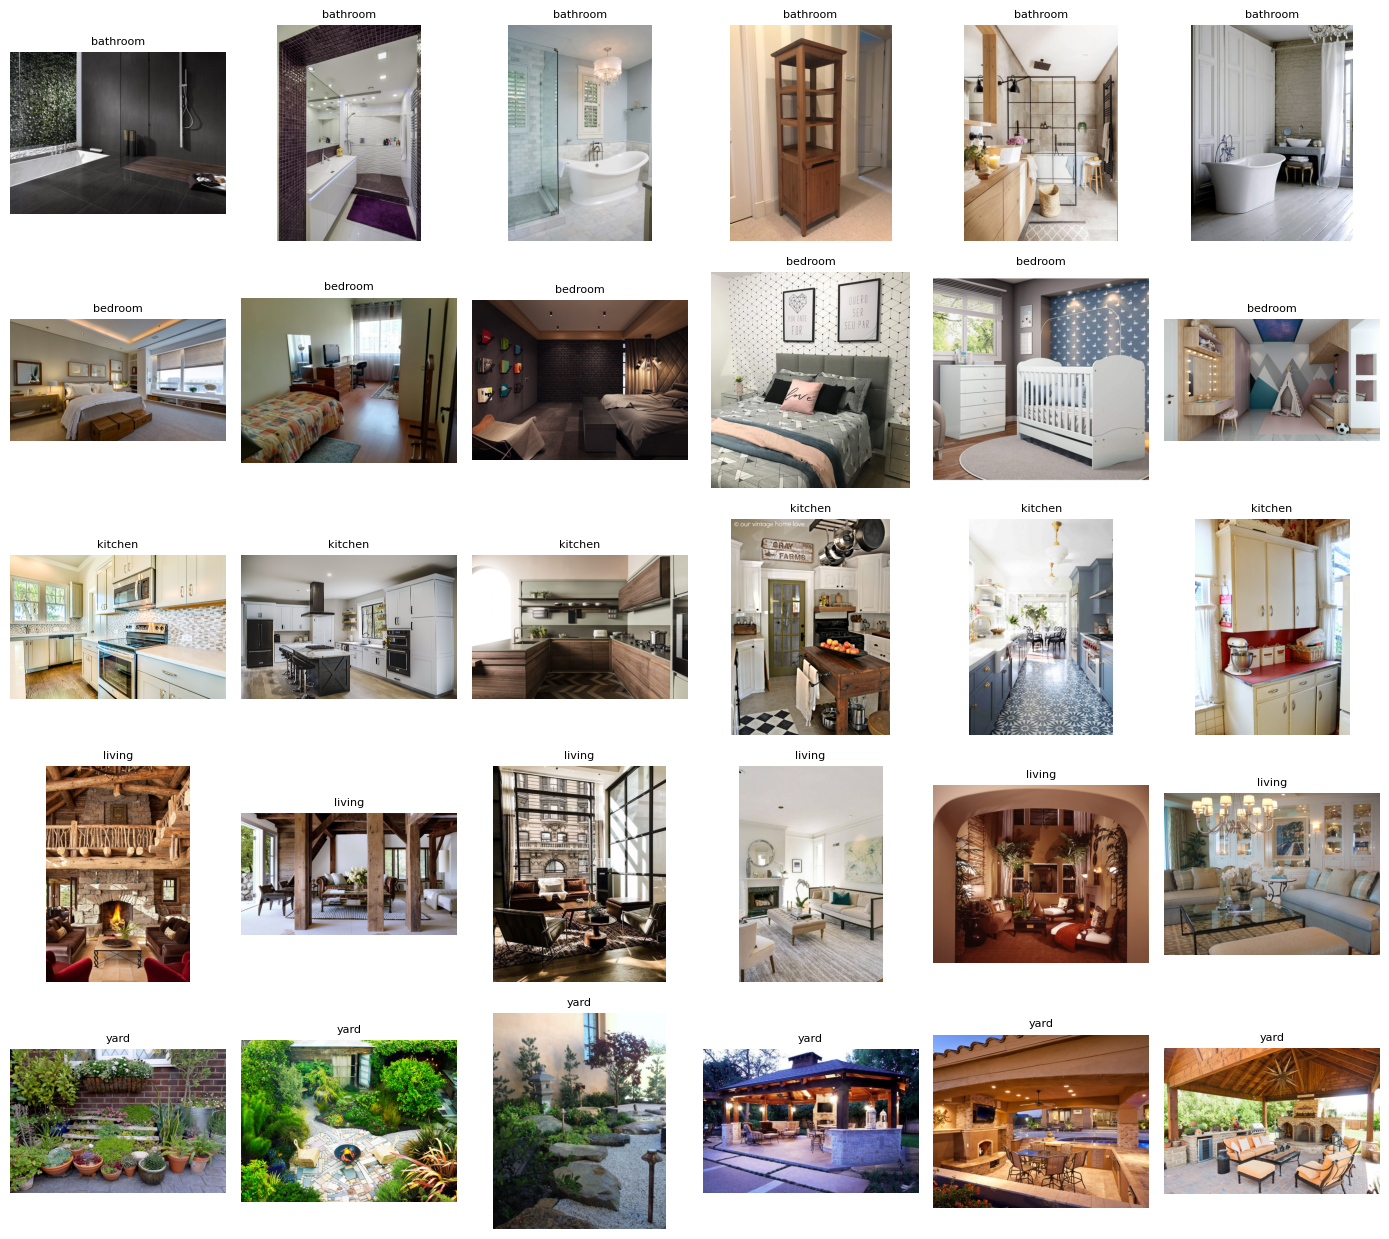

In [ ]:
fig, ejes = plt.subplots(len(CLASES), 6, figsize=(14, 2.5 * len(CLASES)))
for fila, clase in zip(ejes, CLASES):
    archivos = sorted(os.listdir(os.path.join(RUTA_DATOS, clase)))[:6]
    for eje, archivo in zip(fila, archivos):
        eje.imshow(Image.open(os.path.join(RUTA_DATOS, clase, archivo)).convert("RGB"))
        eje.set_title(clase, fontsize=8)
        eje.axis("off")
    for eje in fila[len(archivos):]:
        eje.axis("off")
plt.tight_layout()
plt.show()

## 2. Dividir los datos en entrenamiento, validación y prueba

La partición será estratificada: conserva aproximadamente la proporción de cada clase en los tres grupos. La prueba se reserva hasta la evaluación final y no se utiliza para elegir el modelo ni el umbral.

- 70 % entrenamiento
- 15 % validación
- 15 % prueba

In [ ]:
NOMBRES = CLASES
N_CLASES = len(NOMBRES)
rutas, etiquetas = [], []
for indice, clase in enumerate(NOMBRES):
    carpeta = os.path.join(RUTA_DATOS, clase)
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(EXTENSIONES):
            rutas.append(os.path.join(carpeta, archivo))
            etiquetas.append(indice)

rutas = np.array(rutas)
etiquetas = np.array(etiquetas)

r_ent, r_resto, y_ent, y_resto = train_test_split(
    rutas, etiquetas, test_size=0.30, random_state=SEMILLA, stratify=etiquetas
)
r_val, r_pru, y_val, y_pru = train_test_split(
    r_resto, y_resto, test_size=0.50, random_state=SEMILLA, stratify=y_resto
)

print("Total:", len(rutas))
print(f"Entrenamiento: {len(r_ent)} ({len(r_ent)/len(rutas):.1%})")
print(f"Validación:    {len(r_val)} ({len(r_val)/len(rutas):.1%})")
print(f"Prueba:        {len(r_pru)} ({len(r_pru)/len(rutas):.1%})")

resumen = []
for nombre, y in [("Entrenamiento", y_ent), ("Validación", y_val), ("Prueba", y_pru)]:
    cuenta = np.bincount(y, minlength=N_CLASES)
    resumen.append([nombre] + cuenta.tolist())
display(pd.DataFrame(resumen, columns=["partición"] + NOMBRES))

Total: 5591
Entrenamiento: 3913 (70.0%)
Validación:    839 (15.0%)
Prueba:        839 (15.0%)


,partición,bathroom,bedroom,kitchen,living,yard
0,Entrenamiento,518,758,845,814,978
1,Validación,111,162,181,175,210
2,Prueba,111,163,181,175,209


### 2.1 Crear los conjuntos `tf.data`

Las imágenes se redimensionan a 160 × 160 píxeles. Se mantienen los valores RGB entre 0 y 255; MobileNetV2 aplicará su propio preprocesamiento.

In [ ]:
TAM = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta, etiqueta):
    imagen = tf.io.read_file(ruta)
    imagen = tf.image.decode_image(imagen, channels=3, expand_animations=False)
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, (TAM, TAM))
    return imagen, etiqueta

def crear_dataset(rutas_particion, etiquetas_particion, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((rutas_particion, etiquetas_particion))
    if entrenamiento:
        ds = ds.shuffle(len(rutas_particion), seed=SEMILLA, reshuffle_each_iteration=True)
    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

ds_ent = crear_dataset(r_ent, y_ent, entrenamiento=True)
ds_val = crear_dataset(r_val, y_val)
ds_pru = crear_dataset(r_pru, y_pru)

for imagenes, etiquetas_lote in ds_ent.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Etiquetas:", etiquetas_lote[:10].numpy())

Dimensiones del lote: (32, 160, 160, 3)
Etiquetas: [3 4 3 1 2 3 3 2 3 1]


## 3. Entrenar con *transfer learning* (MobileNetV2)

MobileNetV2 ya ha aprendido patrones visuales con ImageNet. Primero congelamos esa base y entrenamos una cabeza nueva para nuestras cinco clases. Después descongelamos una parte final de la base y hacemos *fine-tuning* con una tasa de aprendizaje pequeña.

In [ ]:
base = keras.applications.MobileNetV2(
    input_shape=(TAM, TAM, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

entrada = keras.Input(shape=(TAM, TAM, 3))
x = keras.applications.mobilenet_v2.preprocess_input(entrada)
x = base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.30)(x)
salida = keras.layers.Dense(N_CLASES, activation="softmax")(x)
modelo = keras.Model(entrada, salida)

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
modelo.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
EPOCAS_CABEZA = 12
hist_cabeza = modelo.fit(
    ds_ent,
    validation_data=ds_val,
    epochs=EPOCAS_CABEZA,
    verbose=1
)
print("Exactitud de validación con base congelada:",
      round(modelo.evaluate(ds_val, verbose=0)[1], 3))

Epoch 1/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 123s 958ms/step - accuracy: 0.7253 - loss: 0.7543 - val_accuracy: 0.8605 - val_loss: 0.4163
Epoch 2/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 139s 935ms/step - accuracy: 0.8500 - loss: 0.4401 - val_accuracy: 0.8749 - val_loss: 0.3756
Epoch 3/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.8643 - loss: 0.3776 - val_accuracy: 0.8760 - val_loss: 0.3637
Epoch 4/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 120s 907ms/step - accuracy: 0.8824 - loss: 0.3471 - val_accuracy: 0.8772 - val_loss: 0.3450
Epoch 5/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 146s 945ms/step - accuracy: 0.8919 - loss: 0.3105 - val_accuracy: 0.8772 - val_loss: 0.3459
Epoch 6/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 111s 903ms/step - accuracy: 0.8965 - loss: 0.3004 - val_accuracy: 0.8653 - val_loss: 0.3538
Epoch 7/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 112s 904ms/step - accuracy: 0.8996 - loss: 0.2834 - val_accuracy: 0.8892 - val_loss: 0.3358
Epoch 8/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 905ms/step - accuracy: 0.9134 - lo

In [ ]:
# Fine-tuning: descongelamos las últimas capas, manteniendo BatchNormalization congeladas
base.trainable = True
for capa in base.layers[:-30]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, keras.layers.BatchNormalization):
        capa.trainable = False

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
EPOCAS_AJUSTE = 8
hist_ajuste = modelo.fit(
    ds_ent,
    validation_data=ds_val,
    epochs=EPOCAS_AJUSTE,
    verbose=1
)
print("Exactitud de validación tras fine-tuning:",
      round(modelo.evaluate(ds_val, verbose=0)[1], 3))

Epoch 1/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9249 - loss: 0.2157 - val_accuracy: 0.8880 - val_loss: 0.3298
Epoch 2/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.9474 - loss: 0.1680 - val_accuracy: 0.8880 - val_loss: 0.3400
Epoch 3/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.9497 - loss: 0.1493 - val_accuracy: 0.8880 - val_loss: 0.3267
Epoch 4/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9586 - loss: 0.1314 - val_accuracy: 0.8892 - val_loss: 0.3195
Epoch 5/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9652 - loss: 0.1034 - val_accuracy: 0.8796 - val_loss: 0.3622
Epoch 6/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9734 - loss: 0.0908 - val_accuracy: 0.8903 - val_loss: 0.3332
Epoch 7/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.9773 - loss: 0.0815 - val_accuracy: 0.8903 - val_loss: 0.3322
Epoch 8/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9801 - loss: 0.0676 - val_accuracy: 0.

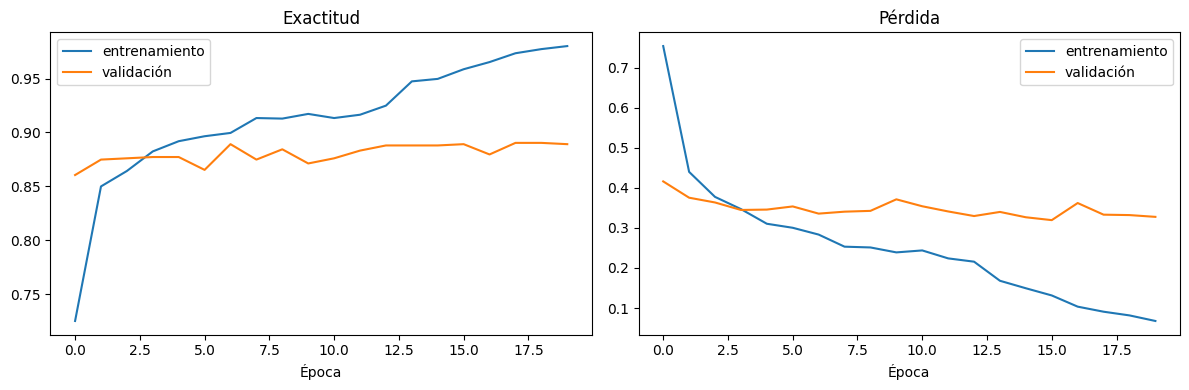

In [ ]:
# Curvas de aprendizaje
historial = {}
for clave in hist_cabeza.history:
    historial[clave] = hist_cabeza.history[clave] + hist_ajuste.history.get(clave, [])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(historial["accuracy"], label="entrenamiento")
ejes[0].plot(historial["val_accuracy"], label="validación")
ejes[0].set_title("Exactitud"); ejes[0].set_xlabel("Época"); ejes[0].legend()
ejes[1].plot(historial["loss"], label="entrenamiento")
ejes[1].plot(historial["val_loss"], label="validación")
ejes[1].set_title("Pérdida"); ejes[1].set_xlabel("Época"); ejes[1].legend()
plt.tight_layout(); plt.show()

## 4. Modelo de referencia entrenado desde cero

Entrenamos una CNN sencilla sin pesos preentrenados. La comparación permite estimar cuánto aporta reutilizar MobileNetV2. Para ahorrar tiempo, la CNN de referencia es deliberadamente pequeña.

In [ ]:
modelo_cero = keras.Sequential([
    keras.Input(shape=(TAM, TAM, 3)),
    keras.layers.Rescaling(1./255),
    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.35),
    keras.layers.Dense(N_CLASES, activation="softmax")
])
modelo_cero.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
hist_cero = modelo_cero.fit(
    ds_ent, validation_data=ds_val, epochs=12, verbose=1
)
print("Exactitud de validación desde cero:",
      round(modelo_cero.evaluate(ds_val, verbose=0)[1], 3))

Epoch 1/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.3693 - loss: 1.3675 - val_accuracy: 0.4410 - val_loss: 1.2593
Epoch 2/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.4339 - loss: 1.2612 - val_accuracy: 0.4827 - val_loss: 1.2321
Epoch 3/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.4365 - loss: 1.2538 - val_accuracy: 0.4803 - val_loss: 1.2034
Epoch 4/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 197s 2s/step - accuracy: 0.4577 - loss: 1.2419 - val_accuracy: 0.5089 - val_loss: 1.1908
Epoch 5/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.4784 - loss: 1.2086 - val_accuracy: 0.5054 - val_loss: 1.1457
Epoch 6/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 200s 2s/step - accuracy: 0.4866 - loss: 1.1980 - val_accuracy: 0.5030 - val_loss: 1.1482
Epoch 7/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.4986 - loss: 1.1815 - val_accuracy: 0.5316 - val_loss: 1.1195
Epoch 8/12
123/123 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.5116 - loss: 1.1564 - val_accu

## 5. Evaluación final en el conjunto de prueba

**A partir de aquí se utiliza la prueba para medir el rendimiento final.** No se debe volver a entrenar ni elegir parámetros mirando estos resultados.

In [ ]:
prob_pru = modelo.predict(ds_pru, verbose=0)
pred_pru = prob_pru.argmax(axis=1)
y_prueba = np.concatenate([y.numpy() for _, y in ds_pru])

print("Exactitud en prueba – MobileNetV2:", round(accuracy_score(y_prueba, pred_pru), 3))
print("F1 macro – MobileNetV2:", round(f1_score(y_prueba, pred_pru, average="macro"), 3))
print("\nInforme por clase:")
print(classification_report(y_prueba, pred_pru, target_names=NOMBRES, zero_division=0))

prob_cero = modelo_cero.predict(ds_pru, verbose=0)
pred_cero = prob_cero.argmax(axis=1)
print("Exactitud en prueba – CNN desde cero:", round(accuracy_score(y_prueba, pred_cero), 3))
print("F1 macro – CNN desde cero:", round(f1_score(y_prueba, pred_cero, average="macro"), 3))

Exactitud en prueba – MobileNetV2: 0.903
F1 macro – MobileNetV2: 0.898

Informe por clase:
              precision    recall  f1-score   support

    bathroom       0.90      0.83      0.86       111
     bedroom       0.92      0.86      0.89       163
     kitchen       0.87      0.92      0.90       181
      living       0.86      0.92      0.89       175
        yard       0.97      0.95      0.96       209

    accuracy                           0.90       839
   macro avg       0.90      0.90      0.90       839
weighted avg       0.90      0.90      0.90       839

Exactitud en prueba – CNN desde cero: 0.553
F1 macro – CNN desde cero: 0.492


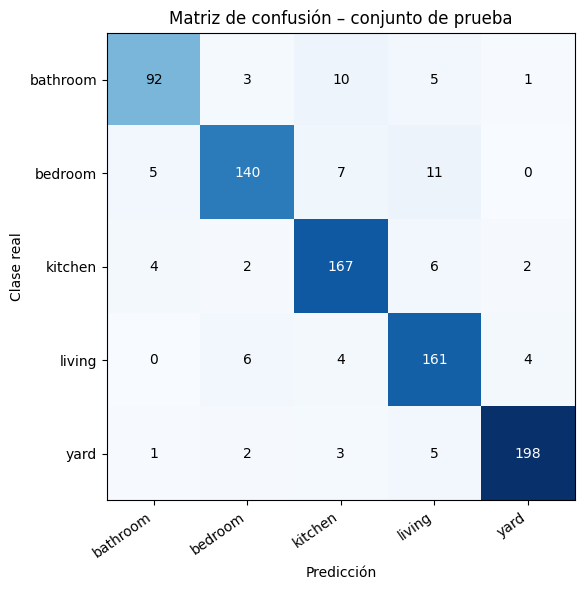

,recall,precisión
bathroom,0.829,0.902
bedroom,0.859,0.915
kitchen,0.923,0.874
living,0.920,0.856
yard,0.947,0.966


Clase más difícil (menor recall): bathroom


In [ ]:
cm = confusion_matrix(y_prueba, pred_pru, labels=range(N_CLASES))
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
for i in range(N_CLASES):
    for j in range(N_CLASES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")
plt.xticks(range(N_CLASES), NOMBRES, rotation=35, ha="right")
plt.yticks(range(N_CLASES), NOMBRES)
plt.xlabel("Predicción"); plt.ylabel("Clase real")
plt.title("Matriz de confusión – conjunto de prueba")
plt.tight_layout(); plt.show()

diag = np.diag(cm).astype(float)
recall_clase = np.divide(diag, cm.sum(axis=1), out=np.zeros(N_CLASES), where=cm.sum(axis=1)>0)
precision_clase = np.divide(diag, cm.sum(axis=0), out=np.zeros(N_CLASES), where=cm.sum(axis=0)>0)
clase_mas_dificil = NOMBRES[int(np.argmin(recall_clase))]
display(pd.DataFrame({"recall": recall_clase, "precisión": precision_clase}, index=NOMBRES).round(3))
print("Clase más difícil (menor recall):", clase_mas_dificil)

## 6. Análisis de errores: mirar las fotografías mal clasificadas

Ordenamos los fallos de mayor a menor confianza. Los errores con confianza alta son especialmente importantes porque el modelo se equivoca con aparente seguridad.

81 imágenes mal clasificadas de 839


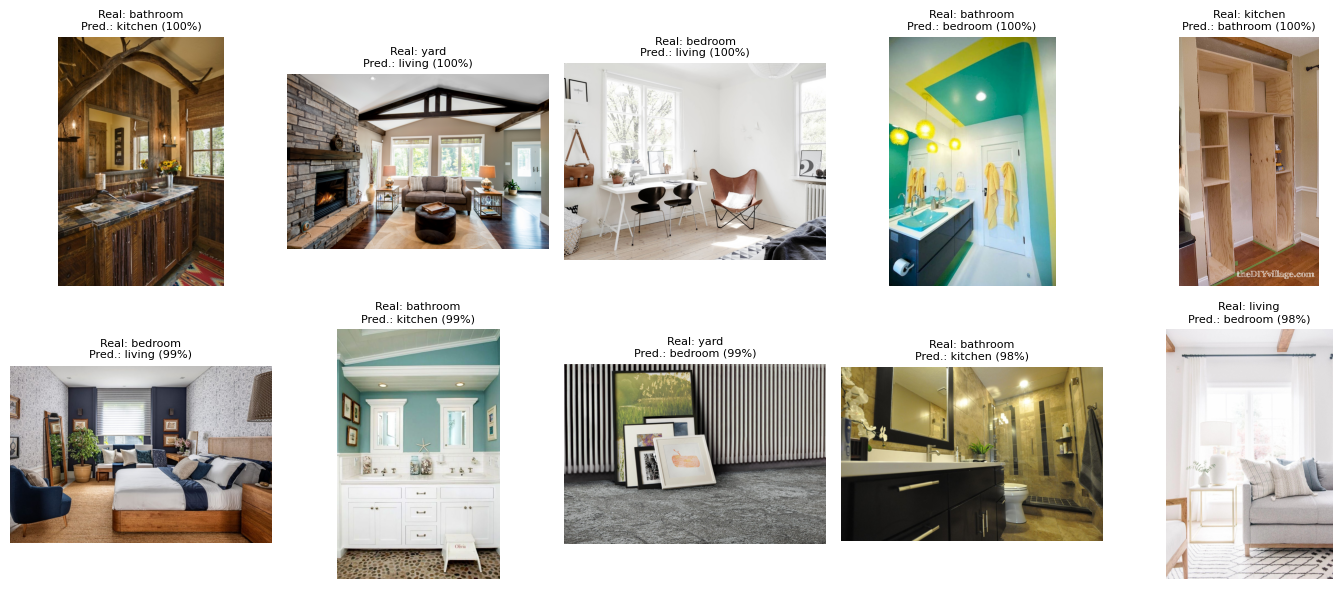

In [ ]:
errores = np.where(pred_pru != y_prueba)[0]
errores_ordenados = errores[np.argsort(-prob_pru.max(axis=1)[errores])]
print(f"{len(errores)} imágenes mal clasificadas de {len(y_prueba)}")

n_mostrar = min(10, len(errores_ordenados))
if n_mostrar:
    fig, ejes = plt.subplots(math.ceil(n_mostrar/5), 5, figsize=(14, 3*math.ceil(n_mostrar/5)))
    ejes = np.array(ejes).reshape(-1)
    for eje in ejes: eje.axis("off")
    for eje, i in zip(ejes, errores_ordenados[:n_mostrar]):
        eje.imshow(Image.open(r_pru[i]).convert("RGB"))
        eje.set_title(
            f"Real: {NOMBRES[y_prueba[i]]}\nPred.: {NOMBRES[pred_pru[i]]} "
            f"({prob_pru[i].max():.0%})", fontsize=8
        )
        eje.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No hay errores en esta prueba. Analiza las imágenes con menor confianza.")

In [ ]:
pares = pd.Series([
    f"{NOMBRES[y_prueba[i]]} → {NOMBRES[pred_pru[i]]}" for i in errores_ordenados
]).value_counts()
display(pares.head(10).rename("número de errores").to_frame())

# Tabla para completar manualmente tras observar las imágenes
filas = []
indices_revision = errores_ordenados[:10] if len(errores_ordenados) else np.argsort(prob_pru.max(axis=1))[:5]
for i in indices_revision:
    filas.append({
        "archivo": os.path.basename(r_pru[i]),
        "verdadera": NOMBRES[y_prueba[i]],
        "predicha": NOMBRES[pred_pru[i]],
        "confianza": round(float(prob_pru[i].max()), 3),
        "hipótesis_visual": "Completar tras observar la fotografía",
        "mejora_propuesta": "Completar"
    })
tabla_errores = pd.DataFrame(filas)
display(tabla_errores)

,número de errores
bedroom → living,11
bathroom → kitchen,10
bedroom → kitchen,7
kitchen → living,6
living → bedroom,6
yard → living,5
bathroom → living,5
bedroom → bathroom,5
living → yard,4
kitchen → bathroom,4


,archivo,verdadera,predicha,confianza,hipótesis_visual,mejora_propuesta
0,bathroom_00414.jpg,bathroom,kitchen,1.000,Completar tras observar la fotografía,Completar
1,yard_00857.jpg,yard,living,0.999,Completar tras observar la fotografía,Completar
2,bedroom_00691.jpg,bedroom,living,0.999,Completar tras observar la fotografía,Completar
3,bathroom_00233.jpg,bathroom,bedroom,0.998,Completar tras observar la fotografía,Completar
4,kitchen_00579.jpg,kitchen,bathroom,0.996,Completar tras observar la fotografía,Completar
5,bedroom_00215.jpg,bedroom,living,0.994,Completar tras observar la fotografía,Completar
6,bathroom_00633.jpg,bathroom,kitchen,0.991,Completar tras observar la fotografía,Completar
7,yard_00317.jpg,yard,bedroom,0.986,Completar tras observar la fotografía,Completar
8,bathroom_00639.jpg,bathroom,kitchen,0.984,Completar tras observar la fotografía,Completar
9,living_00455.jpg,living,bedroom,0.979,Completar tras observar la fotografía,Completar


### Preguntas guía para el informe

1. ¿Los errores se concentran en una clase o en un par de clases?
2. ¿Qué tienen en común las fotografías que fallan (encuadre, iluminación, distancia, objetos, perspectiva)?
3. ¿Hay errores con confianza alta? ¿Qué implica para usar el modelo sin supervisión?
4. ¿Qué fotografías podrían estar mal etiquetadas o no representar bien su clase?
5. ¿Qué mejora concreta propondrías a partir de lo que se observa?

No escribas «faltan datos» como única explicación: la hipótesis debe referirse a algo que se pueda observar en la imagen.

## 7. IA responsable: cobertura y umbral de confianza

El modelo puede abstenerse: si no alcanza la confianza mínima, deriva la imagen a una persona. El umbral se elige con validación; la prueba solo se usa para medir el resultado final.

In [ ]:
def cobertura_y_exactitud(prob, y_real, umbral):
    aceptadas = prob.max(axis=1) >= umbral
    if aceptadas.sum() == 0:
        return 0.0, 0.0
    aciertos = prob.argmax(axis=1)[aceptadas] == y_real[aceptadas]
    return float(aceptadas.mean()), float(aciertos.mean())

prob_val = modelo.predict(ds_val, verbose=0)
umbrales = [0.0, 0.5, 0.7, 0.8, 0.9, 0.95]
tabla_umbrales = pd.DataFrame(
    [cobertura_y_exactitud(prob_val, y_val, u) for u in umbrales],
    index=umbrales,
    columns=["cobertura", "exactitud_aceptadas"]
)
tabla_umbrales.index.name = "umbral"
display(tabla_umbrales.round(3))

,cobertura,exactitud_aceptadas
umbral,,
0.00,1.000,0.889
0.50,0.985,0.901
0.70,0.925,0.927
0.80,0.878,0.954
0.90,0.825,0.968
0.95,0.775,0.975


In [ ]:
# Selecciona el umbral después de observar la tabla de VALIDACIÓN
UMBRAL_ELEGIDO = 0.70

cob, exa = cobertura_y_exactitud(prob_pru, y_prueba, UMBRAL_ELEGIDO)
print(f"Con umbral {UMBRAL_ELEGIDO:.2f}, el modelo decide solo el {cob:.1%} de las fotos.")
print(f"De las fotos aceptadas, acierta el {exa:.1%}.")
print(f"El {1-cob:.1%} restante se deriva a revisión humana.")

Con umbral 0.70, el modelo decide solo el 91.1% de las fotos.
De las fotos aceptadas, acierta el 94.1%.
El 8.9% restante se deriva a revisión humana.


## 8. Demostrador: clasificar una fotografía nueva

Sube una imagen desde tu ordenador. El demostrador devuelve la clase, la confianza y las probabilidades. Si la confianza es inferior al umbral, recomienda revisión humana.

In [ ]:
from google.colab import files

def clasificar_foto(ruta_imagen, modelo_=None, umbral=UMBRAL_ELEGIDO):
    modelo_ = modelo_ or modelo
    img = keras.utils.load_img(ruta_imagen, target_size=(TAM, TAM))
    x = keras.utils.img_to_array(img)
    p = modelo_.predict(np.expand_dims(x, 0), verbose=0)[0]
    confianza = float(p.max())
    clase = NOMBRES[int(p.argmax())] if confianza >= umbral else "revisar a mano"
    probabilidades = dict(zip(NOMBRES, p.round(3)))
    return clase, confianza, probabilidades

subidos = files.upload()
for nombre_archivo in subidos:
    resultado = clasificar_foto(nombre_archivo)
    print("\nImagen:", nombre_archivo)
    print("Resultado:", resultado[0])
    print("Confianza:", f"{resultado[1]:.1%}")
    print("Probabilidades:", resultado[2])

Saving descarga.jpg to descarga (1).jpg

Imagen: descarga (1).jpg
Resultado: yard
Confianza: 100.0%
Probabilidades: {'bathroom': np.float32(0.0), 'bedroom': np.float32(0.0), 'kitchen': np.float32(0.0), 'living': np.float32(0.0), 'yard': np.float32(1.0)}


## 9. Guardar resultados y modelo

Se guardan el modelo entrenado, la matriz de confusión, el informe por clase y la tabla de errores. Descarga los ficheros desde el panel de archivos de Colab.

In [ ]:
modelo.save("modelo_estancias_kaggle.keras")

informe = classification_report(
    y_prueba, pred_pru, target_names=NOMBRES, output_dict=True, zero_division=0
)
pd.DataFrame(informe).transpose().to_csv("metricas_por_clase.csv", encoding="utf-8")
pd.DataFrame(cm, index=NOMBRES, columns=NOMBRES).to_csv("matriz_confusion.csv", encoding="utf-8")
tabla_errores.to_csv("analisis_errores_base.csv", index=False, encoding="utf-8")

print("Ficheros guardados:")
for f in ["modelo_estancias_kaggle.keras", "metricas_por_clase.csv",
          "matriz_confusion.csv", "analisis_errores_base.csv"]:
    print(" -", f)

Ficheros guardados:
 - modelo_estancias_kaggle.keras
 - metricas_por_clase.csv
 - matriz_confusion.csv
 - analisis_errores_base.csv


## 10. Conclusiones para el cliente

Completa este resumen con los resultados que aparecen al ejecutar el cuaderno.

- **Dataset:** House Rooms de Kaggle; cinco clases seleccionadas: bathroom, bedroom, kitchen, living y yard.
- **Número de imágenes:** anota el total y cuántas hay por clase.
- **Partición:** 70 % entrenamiento, 15 % validación y 15 % prueba.
- **Modelo:** MobileNetV2 preentrenada en ImageNet, con cabeza nueva y ajuste fino.
- **Comparación:** compara la exactitud y F1 macro de MobileNetV2 con la CNN entrenada desde cero.
- **Clase más difícil:** utiliza el menor recall.
- **Errores relevantes:** comenta al menos tres fotografías concretas, incluyendo confianza y una hipótesis visual.
- **Uso responsable:** indica el umbral, cobertura, exactitud de las aceptadas y porcentaje derivado a revisión humana.

**Limitaciones:** las categorías del dataset describen estancias/espacios, no tipos de alojamiento. El dataset puede tener sesgos de origen, diferencias de iluminación, calidad y encuadre. El resultado no debe utilizarse como única base para decisiones importantes; conviene mantener revisión humana y probar con fotografías representativas del contexto real de uso.

### Fuente del dataset
- Kaggle: https://www.kaggle.com/datasets/annielu21/house-rooms
- Licencia y condiciones: consulta la ficha de Kaggle antes de reutilizar o redistribuir las imágenes.